# SmartFallMM — Evidence and Reusable Pipeline

**Author: Pratyay Dhar**

**Original Kaggle notebook:** [SmartFallMM notebook](https://www.kaggle.com/code/pratyaydhar/notebook2d06429765)

## Goal

Inspect six recorded experiments, their subject protocol, and the portable model
interfaces without downloading participant data. This notebook is an executed
evidence walkthrough, **not a rerun of the original SmartFallMM experiments**.

The original Kaggle notebook is preserved byte-for-byte next to this file.
Original data and trained checkpoints were not supplied. Scores below are saved
notebook outputs; fresh synthetic tensors are used only for shape checks.


## Setup

Run `python -m pip install -e ".[notebook]"` from the repository root first.
This walkthrough works with the working directory set to the repository root or
its `notebooks/` folder. No credentials or raw dataset paths are required.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import pandas as pd
import torch
from IPython.display import Image, display
from smartfall.models import build_model

ROOT = Path.cwd().resolve()
if not (ROOT / "evidence").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "evidence").is_dir(), "Run from the repository root or notebooks directory"
torch.set_num_threads(1)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Execution device: CPU")

Python: 3.12.14
PyTorch: 2.15.0+cpu
Execution device: CPU


## 1. Verify the source artifact

The hash binds this evidence to the unchanged uploaded notebook. A passing hash
check proves file identity, not that its training results have been reproduced.

In [2]:
manifest = json.loads((ROOT / "evidence/source_manifest.json").read_text())
source = ROOT / manifest["notebook"]
assert hashlib.sha256(source.read_bytes()).hexdigest() == manifest["sha256"]
print("Original notebook SHA-256 verified")
print("Original execution status:", manifest["execution_status"])

Original notebook SHA-256 verified
Original execution status: Stopped at cell 28: missing tensorflow_addons; later cells unexecuted


## 2. Review all six recorded result summaries

The test partition has 2,572 windows: 1,891 ADL and 681 falls. The table displays
percent values for accuracy/precision/recall/F1, with AUC as a fraction.
F1 is **binary fall F1**, not Macro-F1. Exact saved summaries are linked by
zero-based `source_cell`.

In [3]:
records = json.loads((ROOT / "evidence/recorded_metrics.json").read_text())
assert len(records) == 6
assert all(r["status"] == "recorded_not_reproduced" for r in records)
table = pd.DataFrame(records)[["name", "accuracy", "precision", "recall", "f1", "auc", "threshold", "source_cell"]]
for field in ["accuracy", "precision", "recall", "f1"]:
    table[field] = table[field] * 100
display(table.round(4).rename(columns={"accuracy":"accuracy (%)", "precision":"fall precision (%)", "recall":"fall recall (%)", "f1":"fall F1 (%)"}))

,name,accuracy (%),fall precision (%),fall recall (%),fall F1 (%),auc,threshold,source_cell
0,IT student,86.74,70.53,85.76,77.40,0.9472,0.38,8
1,Multimodal teacher,95.96,89.25,96.33,92.66,0.9931,0.30,10
2,IT student + KD,89.00,75.64,86.20,80.58,0.9559,0.44,12
3,LightHART,89.70,77.51,86.05,81.56,0.9556,0.44,21
4,Shared-CNN teacher,94.91,85.26,97.65,91.03,0.9926,0.36,22
5,LightHART + KD,87.29,70.82,88.40,78.64,0.9493,0.50,24


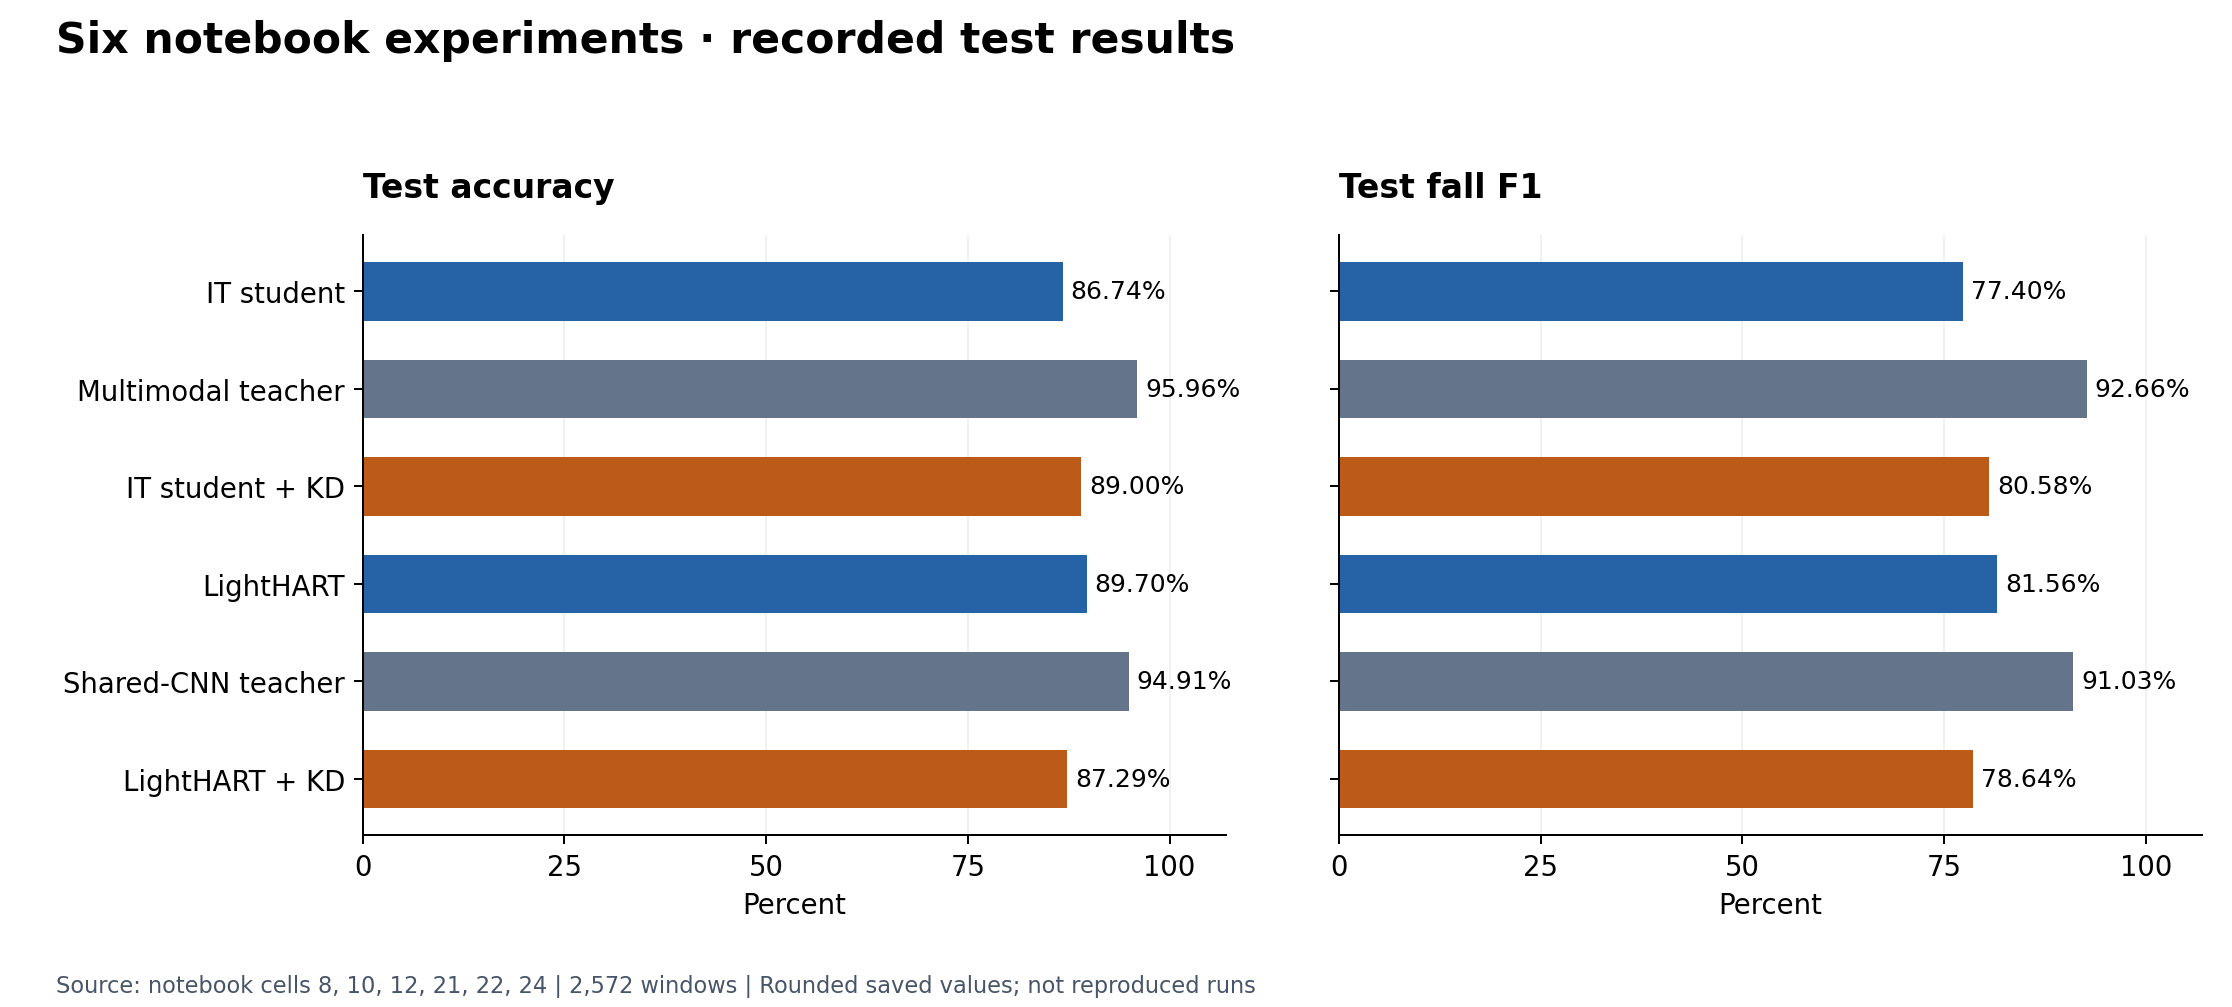

In [4]:
display(Image(filename=str(ROOT / "assets/figures/recorded_results.png"), width=1000, alt="Recorded notebook test accuracy and fall F1; not reproduced"))

**Observation:** IT KD records an F1 increase from 77.40% to 80.58%.
LightHART KD records an F1 decrease from 81.56% to 78.64%. Different training and
initialization settings prevent a controlled causal interpretation. All six
rows remain visible.

## 3. Inspect the configured subject split

The source subject lists are disjoint, but only 10,388 of 13,077 generated windows
are selected. The 2,689 excluded windows represent 17 additional subject IDs.
The test subjects are from the notebook's young group.

In [5]:
subjects = json.loads((ROOT / "configs/subjects.json").read_text())
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not set(subjects[a]) & set(subjects[b])
for split, ids in subjects.items():
    print(f"{split}: {len(ids)} subjects — {ids}")
assert 13077 - (6874 + 942 + 2572) == 2689
print("Excluded windows: 2,689")

train: 26 subjects — [29, 30, 31, 32, 34, 35, 36, 37, 39, 43, 44, 45, 48, 49, 50, 51, 52, 53, 54, 55, 15, 16, 17, 18, 19, 21]
val: 2 subjects — [38, 46]
test: 8 subjects — [56, 57, 58, 59, 60, 61, 62, 63]
Excluded windows: 2,689


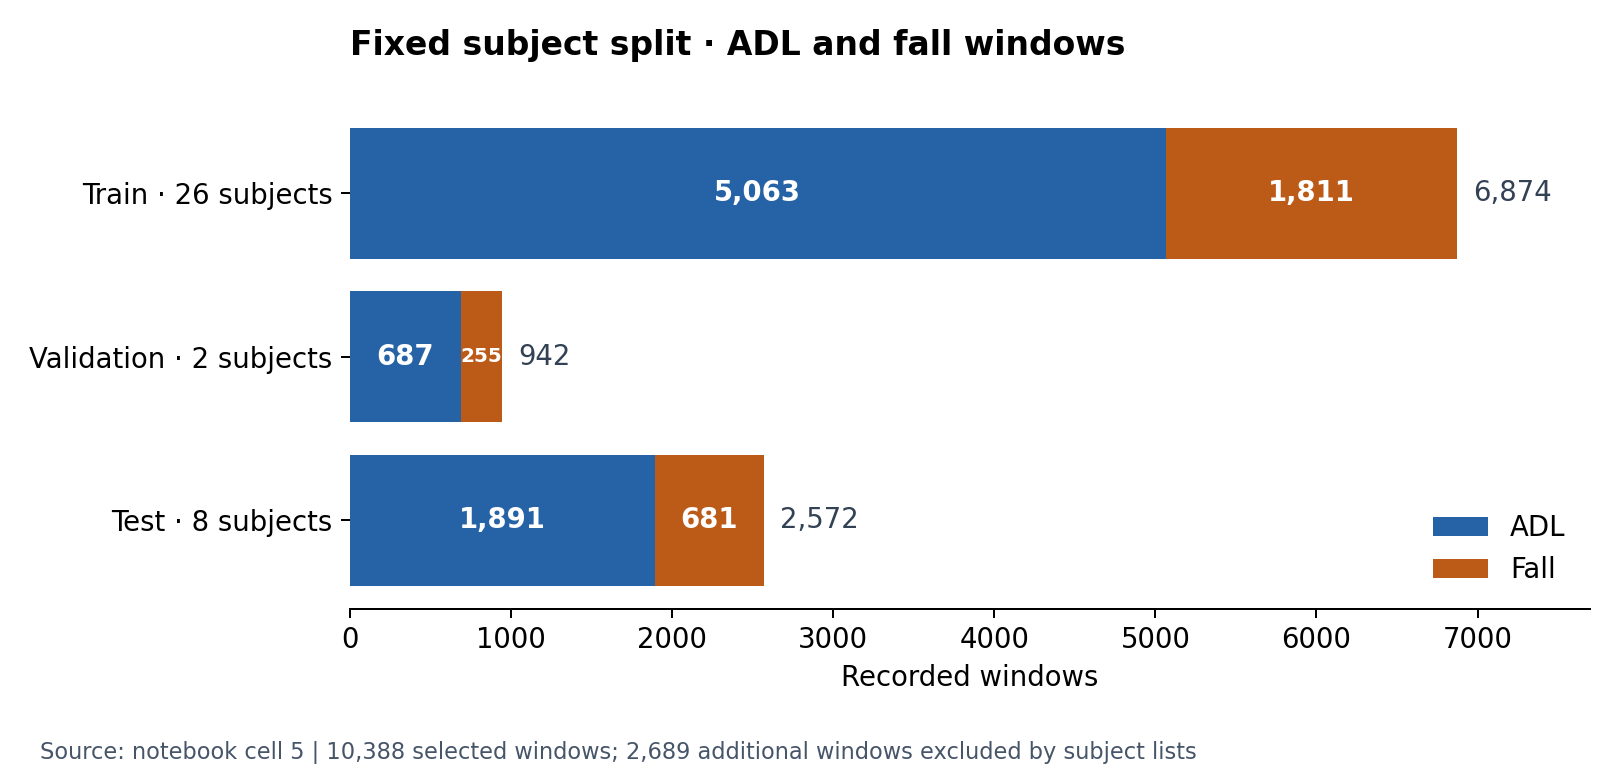

In [6]:
display(Image(filename=str(ROOT / "assets/figures/subject_split.png"), width=850, alt="Recorded ADL and fall counts in disjoint subject partitions"))

## 4. Explore saved validation histories

The source tunes the threshold for validation accuracy every epoch. Checkpoints
also use validation accuracy except the LightHART KD checkpoint, which uses fall
F1 at the accuracy-tuned threshold. Curves use logged rounded values, with no
smoothing or invented epochs.

,experiment,logged epochs,selected epoch,checkpoint criterion
0,IT student,27,15,accuracy
1,Multimodal teacher,30,18,accuracy
2,IT student + KD,12,2,accuracy
3,LightHART,36,21,accuracy
4,Shared-CNN teacher,23,11,accuracy
5,LightHART + KD,19,7,f1


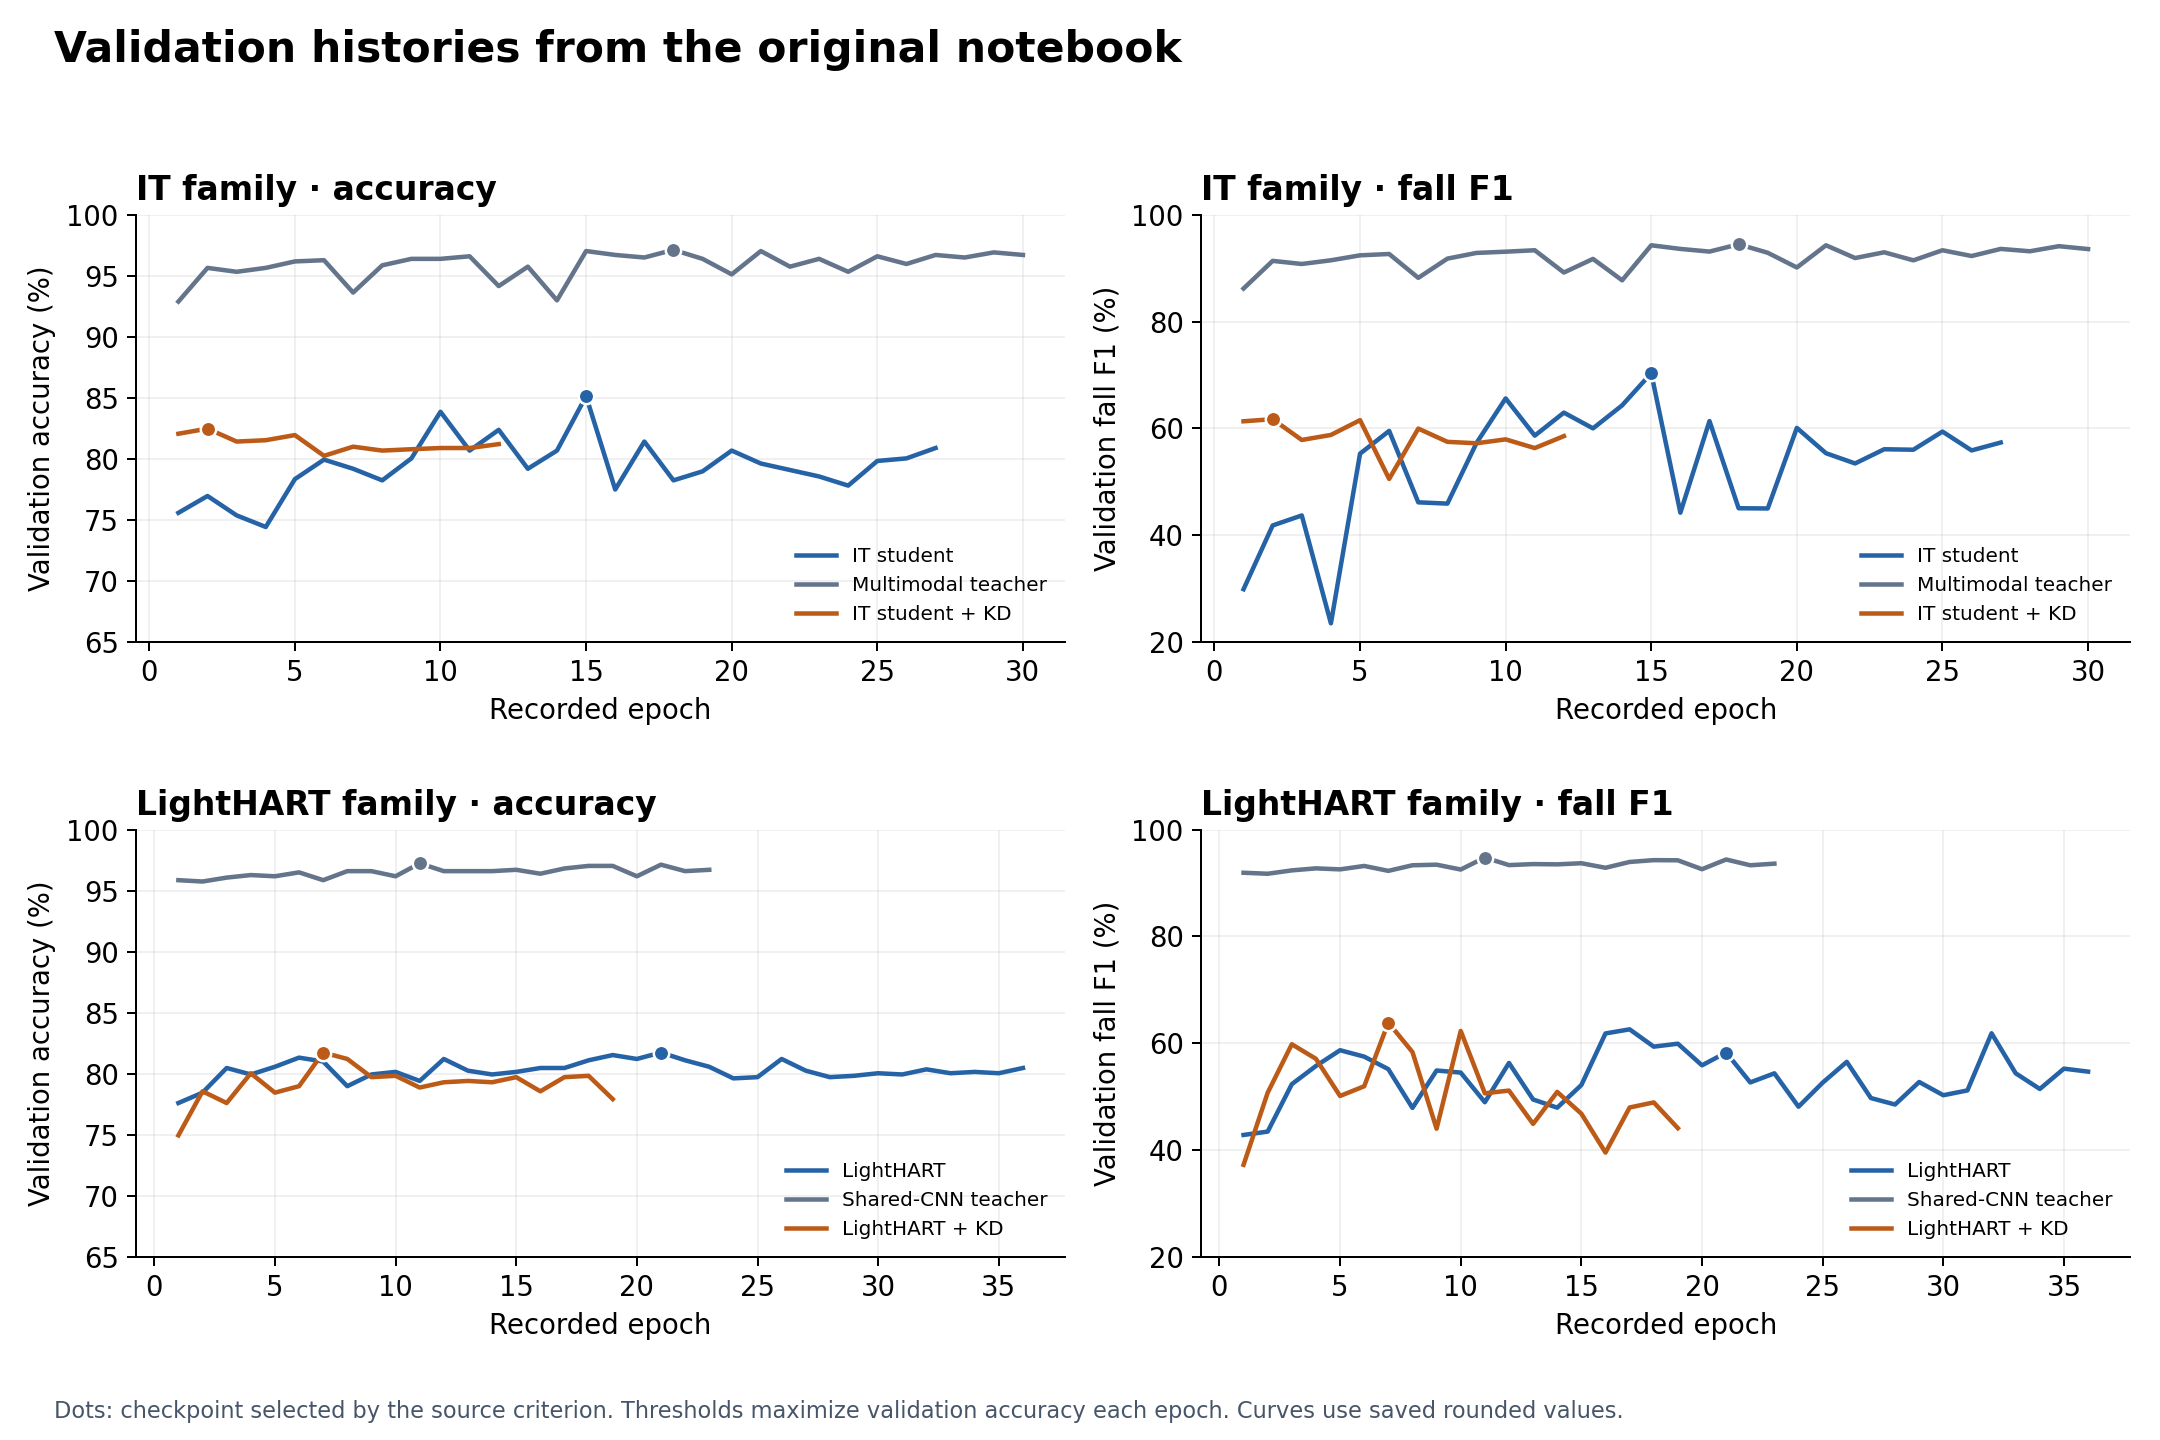

In [7]:
histories = json.loads((ROOT / "evidence/validation_history.json").read_text())
history_summary = []
for rec in histories:
    selection = "f1" if rec["experiment"] == "lighthart_kd" else "accuracy"
    selected = max(rec["validation_history"], key=lambda row: row[selection])
    history_summary.append({"experiment": rec["name"], "logged epochs": len(rec["validation_history"]), "selected epoch": selected["epoch"], "checkpoint criterion": selection})
display(pd.DataFrame(history_summary))
display(Image(filename=str(ROOT / "assets/figures/validation_history.png"), width=1000, alt="Saved validation histories with source-selected checkpoints"))

## 5. Check current model interfaces with synthetic tensors

These are untrained models, instantiated only to validate interfaces. Parameter
counts are computed here; probabilities are deliberately not presented as
real-data predictions. Students receive only accelerometer data in this check.

In [8]:
torch.manual_seed(42)
synthetic = {"accelerometer": torch.randn(2, 64, 4), "skeleton": torch.randn(2, 64, 32, 3)}
interfaces = []
for name in ["it_student", "teacher", "lighthart", "shared_teacher"]:
    model = build_model(name).eval()
    inputs = {"accelerometer": synthetic["accelerometer"]} if name in ["it_student", "lighthart"] else synthetic
    with torch.no_grad():
        outputs = model(inputs)
    assert tuple(outputs[0].shape) == (2, 1)
    assert tuple(outputs[1].shape) == (2, 128)
    interfaces.append({"architecture": name, "parameters": sum(p.numel() for p in model.parameters()), "logits shape": str(tuple(outputs[0].shape)), "KD feature shape": str(tuple(outputs[1].shape))})
display(pd.DataFrame(interfaces))

,architecture,parameters,logits shape,KD feature shape
0,it_student,1170978,"(2, 1)","(2, 128)"
1,teacher,2861400,"(2, 1)","(2, 128)"
2,lighthart,769218,"(2, 1)","(2, 128)"
3,shared_teacher,2189304,"(2, 1)","(2, 128)"


## Checks and next steps

The repository tests compare each refactored architecture with the original
cell definition using identical weights and synthetic inputs. A separate smoke
script exercises paired CSV preprocessing, all six one-epoch training paths,
checkpoint re-evaluation, and prediction. See `evidence/synthetic_validation.json`
for the recorded structural-check status.

**Scientific constraints:** known labels influence peak-window construction;
normalization and DTW use whole groups; filtering is noncausal; skeleton data
helps construct student windows. Current upstream CSV/rate descriptions also
conflict with source assumptions. These details are preserved and discussed in
`docs/SCIENTIFIC_AUDIT.md`. The source export attempt failed and later redefines
a different architecture, so successful edge deployment is not a supported claim.

To run the software checks:

```bash
python -m pytest -q
python scripts/check_evidence.py
python scripts/smoke_pipeline.py
```

To attempt real-data reproduction, follow `docs/REPRODUCING.md` after obtaining
the original data/checkpoints and reviewing the protocol discrepancies.
